# The ten HP500 surveys and the calibrated engine run at each one

**Question:** What did an industrial HP500 secondary cone measure in ten plant surveys, and how close does the calibrated engine get to the throughput of each one at the same setting and feed size?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebooks 01 and 02 of topic 01-getting-started
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- read the survey table of the HP500 secondary cone and say which quantities were measured and which were not;
- explain what the calibrated lane of the engine takes from a survey and what it fixes as machine constants;
- run the engine at each of the ten surveys and put the modelled throughput beside the measured one;
- read the error of each survey and the mean error, and say what a single number hides.

## Setup

Numpy and matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are the survey reader, the calibrated-lane operating point and the engine, with the function that turns the engine's flag texts into stable codes.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.model.crusher import evaluate, operating_from_survey
from pipeline.model.crusher.hp500 import HP500_NOMINAL, HP500_FEED_M, x63_from_f80
from pipeline.core.manifest import flag_codes
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The ten surveys of a Metso HP500 secondary cone crusher at the Minas Rio itabirite iron ore operation. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten survey rows are transcribed from Table A1 of the paper. File read: `data/examples/hp500-surveys.csv`, five columns: the survey number, the feed f80 in mm, the closed-side setting in mm, the feed rate in t/h and the power in kW. The paper reports the product sizes only in figures, so the table has no measured P80.

The cell reads the table through the pipeline's reader, which validates every row, and prints the ranges of the four measured columns.

In [2]:
# Read the survey table with the pipeline's validating reader and print the range of each measured column
report = read_surveys()
surveys = report.accepted
print("accepted rows:", len(surveys), "| rejected:", len(report.rejected))
for name in ("css_mm", "f80_mm", "feed_tph", "power_kw"):
    values = [getattr(s, name) for s in surveys]
    print(f"{name:9s} min {min(values):7.1f}  max {max(values):7.1f}")

accepted rows: 10 | rejected: 0
css_mm    min    38.0  max    55.0
f80_mm    min    47.0  max   140.0
feed_tph  min   813.0  max  1639.0
power_kw  min   187.0  max   355.0


## Method

**Step 1, what a survey gives the engine.** The calibrated lane is built from the Andersen-Whiten fit of Rocha et al. (2024; https://doi.org/10.3390/min14090919, Table 5), linear in the setting and in the feed f80. A survey supplies exactly those two numbers. Everything else is a constant of the machine or an assumption: the throw and the speed are the HP500 nominal values, and the feed shape is rebuilt from the f80 with a Rosin-Rammler uniformity fixed at 0.9, since the paper reports only the f80. Inverting the law at 80 percent passing gives $x_{63} = f_{80} / (\ln 5)^{1/m}$. The cell prints the constants and the operating point of survey 1.

In [3]:
# The machine constants of the lane and the operating point built from survey 1
print("nominal throw and speed:", HP500_NOMINAL, "| feed uniformity m =", HP500_FEED_M)
first = surveys[0]
print("x63 from f80 =", first.f80_mm, "mm:", round(x63_from_f80(first.f80_mm), 3), "mm")
print(operating_from_survey(first.css_mm, first.f80_mm))

nominal throw and speed: Hp500Nominal(throw_mm=34, speed_rpm=360) | feed uniformity m = 0.9
x63 from f80 = 88.0 mm: 51.861 mm
Operating(machine='cone-sec', css_mm=54.0, throw_mm=34, speed_rpm=360, feed_x63_mm=51.8614483895739, feed_m=0.9, ore_axb=677.3, ore_wi=9.0, calibrated=True)


**Step 2, the run.** The cell evaluates the engine at each of the ten surveys, with the calibrated lane on, and lists for each one the measured and the modelled throughput, the error as a percentage of the measurement, the model's P80, and the flag codes the engine raises. The error is $(Q_{model} - Q_{measured}) / Q_{measured}$, so a negative sign means the model undershoots the plant. The last lines give the mean error, which keeps its sign, the mean absolute error, which does not, and how many surveys fall on each side.

In [4]:
# Run the calibrated engine at the ten surveys and list measured and modelled throughput and the flags
runs = [evaluate(operating_from_survey(s.css_mm, s.f80_mm)) for s in surveys]
errors = np.array([(r.throughput_tph - s.feed_tph) / s.feed_tph * 100 for r, s in zip(runs, surveys)])
print("survey  CSS   f80   measured   model    error    P80   flags")
for s, r, e in zip(surveys, runs, errors):
    row = f"{s.survey:6d} {s.css_mm:5.0f} {s.f80_mm:5.0f} {s.feed_tph:9.0f} {r.throughput_tph:8.1f}"
    print(row, f"{e:+7.1f} %", f"{r.p80:6.2f}   {flag_codes(r)}")
print("mean error:", round(float(errors.mean()), 2), "% | mean absolute error:", end=" ")
print(round(float(np.abs(errors).mean()), 2), "%")
print("under-predicted:", int((errors < 0).sum()), "| over-predicted:", int((errors > 0).sum()))

survey  CSS   f80   measured   model    error    P80   flags
     1    54    88      1639   1208.9   -26.2 %  32.56   []
     2    54    84      1267   1208.9    -4.6 %  31.36   []
     3    48    47      1240   1106.7   -10.7 %  21.23   ['pass_through', 'f80_lt_css']
     4    48    88      1034   1106.7    +7.0 %  30.80   []
     5    48    62      1124   1106.7    -1.5 %  24.54   []
     6    40    79       813    970.5   +19.4 %  26.54   []
     7    38   140      1050    936.4   -10.8 %  36.60   []
     8    44   123      1138   1038.6    -8.7 %  35.69   []
     9    40    81       820    970.5   +18.4 %  26.97   []
    10    55    81      1334   1225.9    -8.1 %  30.72   []
mean error: -2.6 % | mean absolute error: 11.55 %
under-predicted: 7 | over-predicted: 3


The figure puts the ten pairs on a parity plot: a point on the diagonal is a perfect prediction, and a point under it is a model that undershoots. The labels are the survey numbers.

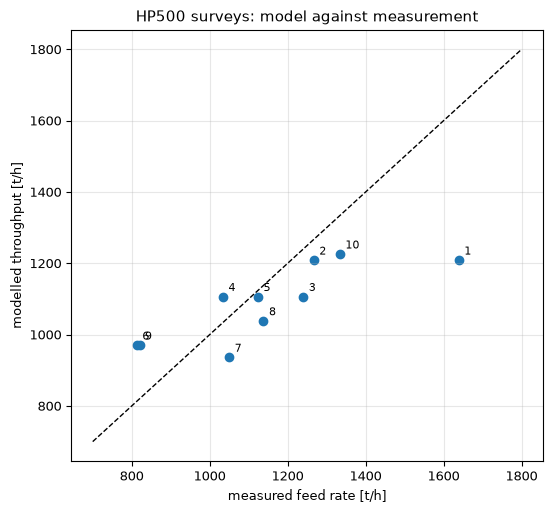

In [5]:
# Parity plot of modelled against measured throughput, labelled by survey
measured = np.array([s.feed_tph for s in surveys])
modelled = np.array([r.throughput_tph for r in runs])
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([700, 1800], [700, 1800], "k--", lw=1)
ax.scatter(measured, modelled)
for s, x, y in zip(surveys, measured, modelled):
    ax.annotate(str(s.survey), (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("measured feed rate [t/h]")
ax.set_ylabel("modelled throughput [t/h]")
ax.set_title("HP500 surveys: model against measurement")
fig.tight_layout()
plt.show()

The points scatter around the diagonal with a slight tendency to fall under it: seven are below and three above, and the farthest, survey 1, lies at 1639 t/h measured against 1209 modelled. The vertical structure is the clue to why: the modelled values come in a few levels, 1209, 1107, 970 and others, while the measured values spread freely, because the engine's capacity depends on the setting and not on the feed f80. The figure shows how far each point is, not why; the next figure plots the same data against the setting.

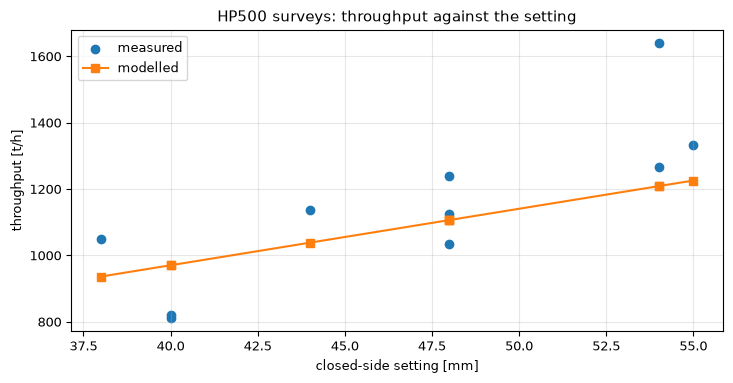

measured at 54 mm [t/h]: [1639. 1267.] | spread: 372.0


In [6]:
# Measured and modelled throughput against the closed-side setting
settings = np.array([s.css_mm for s in surveys])
order = np.argsort(settings)
fig, ax = plt.subplots()
ax.scatter(settings, measured, label="measured")
ax.plot(settings[order], modelled[order], "s-", color="tab:orange", label="modelled")
ax.set_xlabel("closed-side setting [mm]")
ax.set_ylabel("throughput [t/h]")
ax.set_title("HP500 surveys: throughput against the setting")
ax.legend()
fig.tight_layout()
plt.show()
at_54 = measured[settings == 54]
print("measured at 54 mm [t/h]:", at_54, "| spread:", at_54.max() - at_54.min())

The model's line is a function of the setting alone: it rises from 936 t/h at 38 mm to 1226 t/h at 55 mm, a smooth path through the cloud. The measured points follow the same trend, and around it they scatter by up to 372 t/h at the same setting (surveys 1 and 2, at 54 mm, measured 1639 and 1267 t/h, the spread the last line printed). That scatter is what the model leaves unexplained, whether it is the feed, the ore blend, or the state of the liners, and one setting cannot give two throughputs. The figure supports a trend claim, not a prediction claim for an individual survey.

**Step 3, what the engine reads from the f80.** The scatter of the measured throughput at one setting raises the question of what the engine does with the other survey variable. The cell holds the setting at 48 mm, the one of surveys 3, 4 and 5, and runs the calibrated engine at five feed sizes from 47 to 140 mm, the range of the surveys.

In [7]:
# Run the calibrated engine at a fixed setting of 48 mm over the f80 range of the surveys
for f80_mm in (47, 60, 90, 120, 140):
    r = evaluate(operating_from_survey(48, f80_mm))
    print(f"f80 {f80_mm:4d} mm: throughput {r.throughput_tph:7.1f} t/h  P80 {r.p80:5.2f} mm", end="")
    print(f"  reduction ratio {r.reduction_ratio:4.2f}")

f80   47 mm: throughput  1106.7 t/h  P80 21.23 mm  reduction ratio 2.22
f80   60 mm: throughput  1106.7 t/h  P80 24.21 mm  reduction ratio 2.47
f80   90 mm: throughput  1106.7 t/h  P80 31.39 mm  reduction ratio 2.75
f80  120 mm: throughput  1106.7 t/h  P80 36.04 mm  reduction ratio 3.00
f80  140 mm: throughput  1106.7 t/h  P80 38.91 mm  reduction ratio 3.06


The throughput is exactly the same, 1106.7 t/h, at every feed size, while the product P80 moves from 21.23 to 38.91 mm. In this engine the feed size sets the product and the setting sets the tonnage. That is the capacity law of topic 04, which has no feed term, and it is the reason the model's points in the second figure lie on a line. It is also an assumption worth knowing: in a real plant a coarser feed does change the rate at which the crusher can be fed, and the surveys 3, 4 and 5, which share a setting and differ in f80, measured 1240, 1034 and 1124 t/h.

**Step 4, the support of the calibration.** The fit is valid for settings from 38 to 55 mm and feed f80 from 47 to 140 mm, the range of the ten surveys. The engine's envelope gate flags a calibrated point outside it as extrapolating, with the codes `css_outside_calibrated` and `f80_outside_calibrated`, and it tests the F80 that the feed declares, the one of the untruncated Rosin-Rammler law, and not the F80 the engine works with on its grid. The cell evaluates four points, one inside the support, two with the setting outside and one with a feed of 180 mm, and prints the declared f80, the engine's own F80 and the gate's verdict.

In [8]:
# Evaluate four calibrated points and print the declared f80, the engine's F80 and the envelope gate's verdict
for css_mm, f80_mm in ((46, 90), (30, 90), (60, 100), (46, 180)):
    r = evaluate(operating_from_survey(css_mm, f80_mm))
    print(f"CSS {css_mm} mm, declared f80 {f80_mm} mm: engine F80 {r.f80:6.1f} mm,", end=" ")
    print(f"outside the support: {r.out_of_envelope}, codes {list(r.envelope_codes)}")

CSS 46 mm, declared f80 90 mm: engine F80   86.4 mm, outside the support: False, codes []
CSS 30 mm, declared f80 90 mm: engine F80   86.4 mm, outside the support: True, codes ['css_outside_calibrated']
CSS 60 mm, declared f80 100 mm: engine F80   94.2 mm, outside the support: True, codes ['css_outside_calibrated']
CSS 46 mm, declared f80 180 mm: engine F80  135.8 mm, outside the support: True, codes ['f80_outside_calibrated']


All three points outside the surveyed range are flagged, and the one inside is not. The two with a setting outside 38 to 55 mm raise `css_outside_calibrated`. The point with a feed of 180 mm raises `f80_outside_calibrated`, although the engine's own F80 for it, 135.8 mm, is inside the support: the engine's grid stops at 256 mm, which cuts the coarse feed (notebook 01 of topic 02), but the gate reads the declared f80 and so is not fooled by the cut. What the flag still cannot do is say that a point inside the support is accurate: it is evidence of extrapolation when it is raised, and its absence is not evidence of interpolation.

## Results

**Answer:** the calibrated engine's mean absolute throughput error over the ten surveys is 11.55 percent, with individual errors from -26.2 percent (survey 1, 1209 against 1639 t/h) to +19.4 percent (survey 6, 970 against 813 t/h), seven surveys under-predicted and three over-predicted, and a mean error of -2.6 percent. Survey 3 is the one the engine flags: its f80 of 47 mm is below its 48 mm setting, so the engine raises `pass_through` and `f80_lt_css` and marks the point invalid, although its throughput error, -10.7 percent (1107 against 1240 t/h), is close to the mean absolute error.

The first figure shows a mild undershoot and the second explains the scatter: the engine's throughput is a function of the setting, so it follows the trend of the plant and cannot follow the survey-to-survey variation at one setting (372 t/h of spread at 54 mm). A validator would conclude that the engine has the right order of magnitude and the right trend on the one quantity the plant measured as a rate, and that an 11.55 percent mean error on ten points is a descriptive number, not a performance guarantee: it was computed in sample, with the constants of the paper that were fitted to the same surveys. Notebook 02 reads the errors one by one, and topic 06 asks what survives a held-out validation.

## Summary

A survey gives the calibrated engine a setting and an f80; the rest of the machine and the feed shape are fixed. On the ten HP500 surveys the engine's throughput follows the plant's trend with a mean absolute error near 12 percent and a slight undershoot, and it cannot reproduce the variation of the plant at a given setting. The flagged survey 3 shows the engine's own refusal at work. Notebook 02 takes the comparison further, to the product size and the power, and to the questions each one raises.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193